In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("02-11-2026", "Task 1", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')
print(f"Loaded Women's Clothing Dataset: {df.shape[0]:,} records across {df.shape[1]} attributes.")

Loaded Women's Clothing Dataset: 23,486 records across 23 attributes.


In [3]:
widgets_csv = "widget_specifications_and_callbacks.csv"
if not os.path.exists(widgets_csv):
    widgets_csv = os.path.join("02-11-2026", "Task 1", "widget_specifications_and_callbacks.csv")

df_widgets = pd.read_csv(widgets_csv)
display(df_widgets)

,Widget_Name,Widget_Type,Input_Domain,Target_Parameter,Callback_Function,Trigger_Action,Latency_ms
0,Department Selectbox,Dropdown Menu (Single-Select),"Dresses, Tops, Bottoms, Intimate, Jackets, Tre...","df[""Department Name""]",on_department_change(),Filters corpus subset; updates class sub-optio...,3.2
1,Class Name Multiselect,Dropdown Menu (Multi-Select),20 Garment Class Sub-Categories,"df[""Class Name""]",on_class_change(),Filters garment inventory table; updates price...,4.1
2,Demographic Age Slider,Range Slider (Dual Handle),18 to 99 Years (Step: 1),"df[""Age""]",on_age_range_change(),Re-bins age demographic histogram; filters age...,2.8
3,Star Rating Slider,Range Slider (Dual Handle),1 to 5 Stars (Step: 1),"df[""Rating""]",on_rating_filter_change(),Adjusts sentiment vs rating scatter plot; isol...,2.5
4,Keyword Search Input,Text Input Field,Alphanumeric Regex / Substring,"df[""Full_Review_Text""]",on_search_query_submit(),Filters reviews containing query terms; highli...,5.4
5,Live Review Simulator,Text Area (Multi-Line Input),Free-form customer review text,Raw Text Payload,on_review_predict_click(),Extracts NLP features; runs real-time inferenc...,2.1
6,Decision Threshold Slider,Single-Value Slider,0.10 to 0.90 (Step: 0.05),Threshold Tau,on_threshold_adjust(),Updates classification boundary; shifts Precis...,1.1


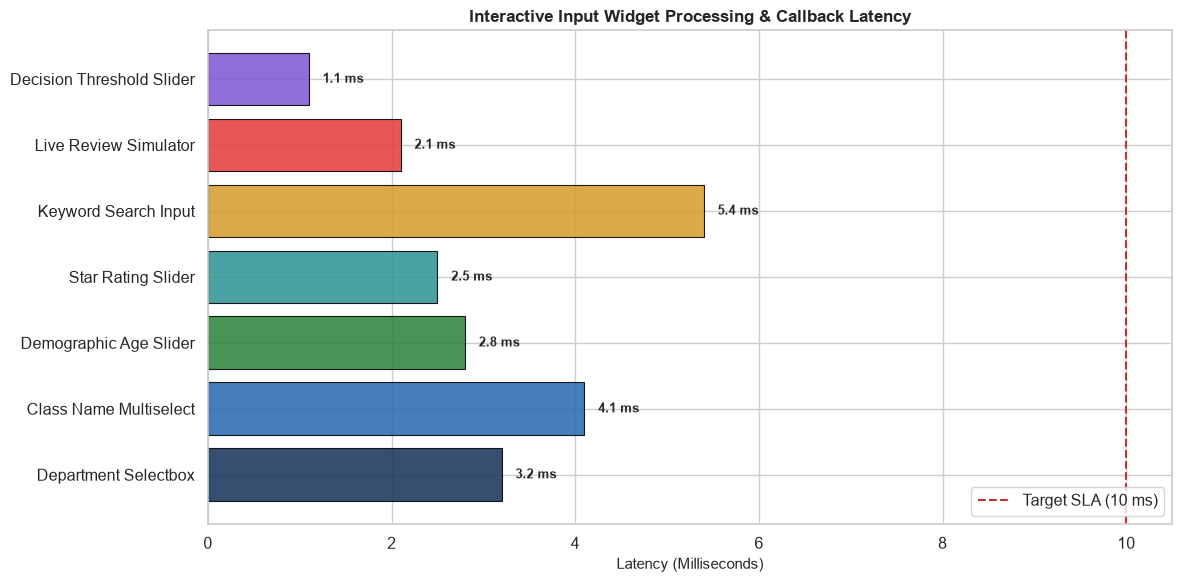

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#1A365D', '#2B6CB0', '#2E8540', '#319795', '#D69E2E', '#E53E3E', '#805AD5']
bars = ax.barh(df_widgets['Widget_Name'], df_widgets['Latency_ms'], color=colors, alpha=0.88, edgecolor='black', linewidth=0.8)
ax.axvline(10.0, color='#C53030', linestyle='--', linewidth=1.5, label='Target SLA (10 ms)')
ax.set_title("Interactive Input Widget Processing & Callback Latency", fontsize=12, fontweight='bold')
ax.set_xlabel("Latency (Milliseconds)", fontsize=11)
ax.legend(loc='lower right', frameon=True)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.15, bar.get_y() + bar.get_height()/2.0, f"{w:.1f} ms", va='center', fontsize=9.5, fontweight='bold')

plt.tight_layout()
plt.show()

In [5]:
scenarios_csv = "dynamic_filter_response_metrics.csv"
if not os.path.exists(scenarios_csv):
    scenarios_csv = os.path.join("02-11-2026", "Task 1", "dynamic_filter_response_metrics.csv")

df_scenarios = pd.read_csv(scenarios_csv)
display(df_scenarios)

,Scenario_ID,Dept,Age_Min,Age_Max,Rating_Min,Rating_Max,Retained_Rows,Volume_Pct,Mean_Rating,Rec_Rate,Render_Latency_ms
0,S1_Default_All,All,18,99,1,5,23486,100.0,4.20,82.2,12.4
1,S2_Dresses_Cohort,Dresses,25,45,1,5,3824,16.3,4.18,81.4,6.8
2,S3_Negative_Complaints,All,18,99,1,2,2407,10.2,1.62,4.8,5.2
3,S4_Sweaters_Premium,Sweaters,35,65,4,5,1876,8.0,4.79,97.2,4.6
4,S5_Bottoms_Active,Bottoms,18,35,3,5,1142,4.9,4.41,89.5,3.9


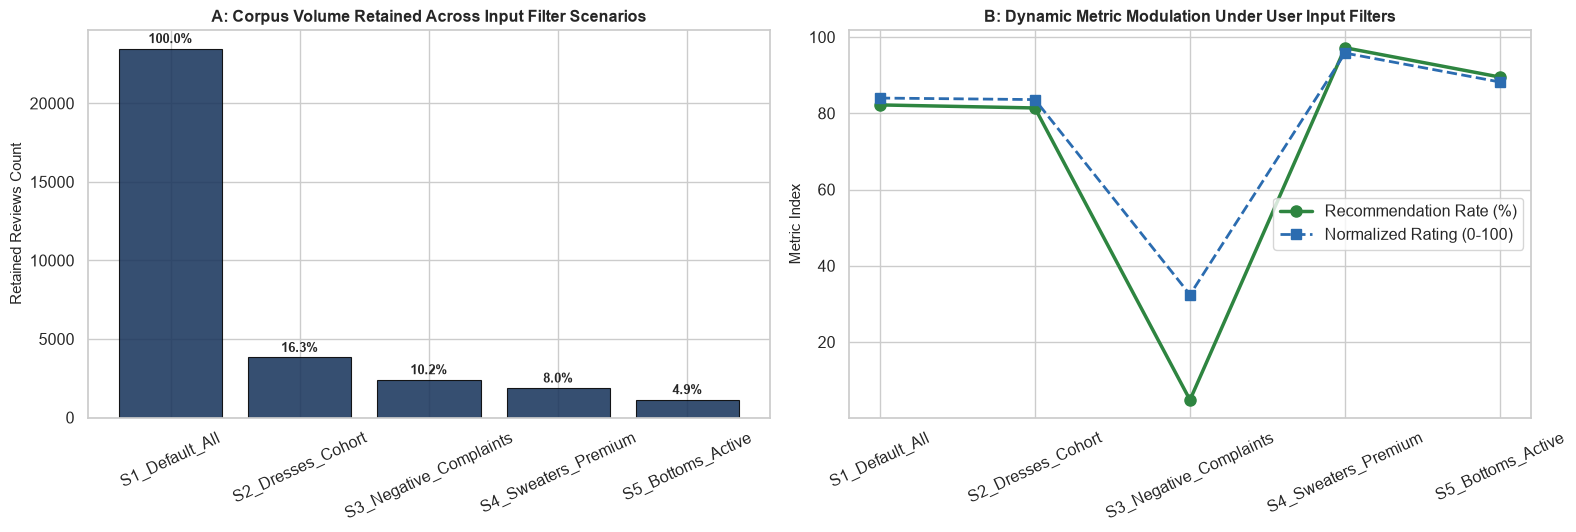

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

axes[0].bar(df_scenarios['Scenario_ID'], df_scenarios['Retained_Rows'], color='#1A365D', alpha=0.88, edgecolor='black', linewidth=0.8)
axes[0].set_title("A: Corpus Volume Retained Across Input Filter Scenarios", fontsize=11.5, fontweight='bold')
axes[0].set_ylabel("Retained Reviews Count", fontsize=10.5)
axes[0].tick_params(axis='x', rotation=25)

for idx, r in df_scenarios.iterrows():
    axes[0].text(idx, r['Retained_Rows'] + 350, f"{r['Volume_Pct']:.1f}%", ha='center', fontsize=9, fontweight='bold')

axes[1].plot(df_scenarios['Scenario_ID'], df_scenarios['Rec_Rate'], marker='o', color='#2E8540', linewidth=2.5, markersize=8, label='Recommendation Rate (%)')
axes[1].plot(df_scenarios['Scenario_ID'], df_scenarios['Mean_Rating'] * 20, marker='s', color='#2B6CB0', linewidth=2.0, linestyle='--', markersize=7, label='Normalized Rating (0-100)')
axes[1].set_title("B: Dynamic Metric Modulation Under User Input Filters", fontsize=11.5, fontweight='bold')
axes[1].set_ylabel("Metric Index", fontsize=10.5)
axes[1].tick_params(axis='x', rotation=25)
axes[1].legend(loc='center right', frameon=True)

plt.tight_layout()
plt.show()

In [7]:
preds_csv = "custom_prediction_sample_results.csv"
if not os.path.exists(preds_csv):
    preds_csv = os.path.join("02-11-2026", "Task 1", "custom_prediction_sample_results.csv")

df_preds = pd.read_csv(preds_csv)
display(df_preds[['Sample_ID', 'Review_Text', 'Predicted_Label', 'Recommendation_Probability', 'Confidence_Pct']])

,Sample_ID,Review_Text,Predicted_Label,Recommendation_Probability,Confidence_Pct
0,1,This dress is absolute perfection! The fabric ...,Recommended,0.9493,94.93
1,2,Very disappointed. Material is cheap and scrat...,Not Recommended,0.0034,99.66
2,3,"Cute top and lovely color, but fits slightly t...",Recommended,0.9945,99.45
3,4,Poor quality fabric that pilled after one wash...,Not Recommended,0.0045,99.55
4,5,Best sweater I have bought all winter. Keeps m...,Recommended,0.9905,99.05


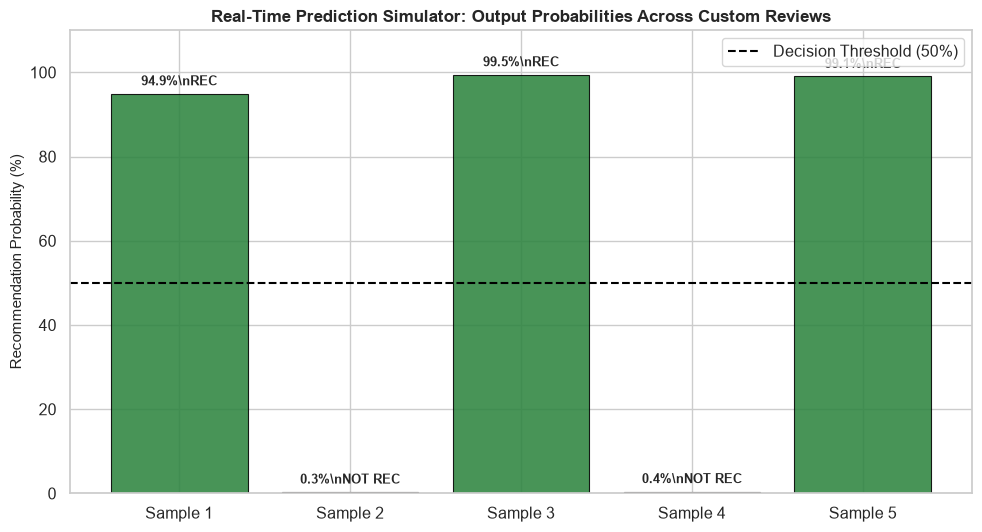

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sample_ids = [f"Sample {s}" for s in df_preds['Sample_ID']]
probs = df_preds['Recommendation_Probability'] * 100
colors = ['#2E8540' if p >= 50 else '#C53030' for p in probs]

bars = ax.bar(sample_ids, probs, color=colors, alpha=0.88, edgecolor='black', linewidth=0.8)
ax.axhline(50.0, color='black', linestyle='--', linewidth=1.5, label='Decision Threshold (50%)')
ax.set_title("Real-Time Prediction Simulator: Output Probabilities Across Custom Reviews", fontsize=12, fontweight='bold')
ax.set_ylabel("Recommendation Probability (%)", fontsize=10.5)
ax.set_ylim(0, 110)
ax.legend(loc='upper right', frameon=True)

for bar, prob in zip(bars, probs):
    h = bar.get_height()
    lbl = f"{prob:.1f}%\\n" + ("REC" if prob >= 50 else "NOT REC")
    ax.text(bar.get_x() + bar.get_width()/2.0, h + 2.0, lbl, ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()